# 26 · The JND loss against the SSIM loss, on the two best models

The perceptual repo beside this one (`perceptual_jnd_loss.py`, its spec §3) holds a differentiable JND metric: the
visible error in just-noticeable differences, after the eye's contrast sensitivity, a brightness gain and masking.
This notebook asks whether training on it gives pictures that look better than training on the loss every model here
uses, `metrics.ssim_l1_loss` (84% luma SSIM, 16% RGB L1).

Two bodies, the best two in this folder:

- **told 24×2** - notebook 22's, what desktop-streamer runs as `upscale.onnx`;
- **fast q24** with its frozen 4×4 skip - notebook 24's drop-in for 60 fps on a GTX 1660 Ti.

Each is trained two ways on notebook 21's pairs, at seeds 0 and 1, with the same data, Adam from 1e-3, batch 32 and
the same halving schedule:

1. **SSIM loss** - notebook 22's and 24's own trainings, loaded from their run files; best epoch by SSIM-Y.
2. **JND loss** - `PerceptualJNDLoss` with the settings in `helpers/jnd_settings.json` (45 px a degree, 64 px tiles,
   d / (d + 1) a picture); best epoch by the same JND on the validation patches.

A judge that is also a loss favours the model trained on it: SSIM-Y and PSNR favour the first, JND and its MOS the
second. So both are also judged by two scores neither trained on - **LPIPS**, fitted to people's choices between
distorted patches, and **GMSD** - and by looking at them, on patches and on whole frames the host's stream made.

In [1]:
"""Settings."""

import json
import os
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from IPython.display import Image as Show, display
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset

os.environ["DATASETS_DIR"] = "/mnt/d/datasets"   # where the datasets are: set before helpers is imported

from helpers import degrade, judges, metrics, models, patches, sources, training
from helpers.training import DEVICE

PAIRS_DIR = sources.ROOT / "upscale" / "qp_slice_pairs"            # notebook 21
RUN_DIR = training.CHECKPOINT_DIR / "jnd_runs"                     # the JND-loss trainings, saved every epoch
SAMPLES = training.SAMPLE_DIR / "26_jnd"                           # pictures, written to look at

QP_MAX = 51
CONDITIONS = ("qp", "deblocked", "intra")
BATCH_SIZE, LEARNING_RATE, MAX_EPOCHS = 32, 1e-3, 500
SEEDS = (0, 1)
LOSSES = ("SSIM loss", "JND loss")
# the two bodies: their arguments, and the run files of their SSIM-loss trainings (notebooks 22 and 24)
BODIES = {
    "told 24x2": {"arguments": dict(conditions=3, width=24, blocks=2, stem=3),
                  "ssim_runs": training.CHECKPOINT_DIR / "qp_slice_runs" / "told_QP_frame_seed{seed}.pt"},
    "fast q24": {"arguments": dict(width=24, stem=4, blocks=1, skip="truncated"),
                 "ssim_runs": training.CHECKPOINT_DIR / "fast_runs" / "q24_frozen_skip_seed{seed}.pt"},
}
# validation sources by their YouTube-8M topic: a label of the video, not of what each picture shows
SCREEN_TOPICS = {"Computer", "Font", "IPad", "IPhone", "Microsoft_Windows", "Office", "Personal_computer", "Screenshot",
                 "Text_messaging", "Web_page", "Website"}
GAME_TOPICS = {"Angry_Birds", "Counter-Strike_video_game", "Euro_Truck_Simulator_2", "Grand_Theft_Auto_V", "Minecraft",
               "RuneScape", "Sprite_computer_graphics", "Strategy_video_game", "Terraria", "Total_War_series",
               "Touhou_Project", "Video_game"}

training.seed_everything(0)
SAMPLES.mkdir(parents=True, exist_ok=True)
print("perceptual repo:", judges.PERCEPTUAL_DIR)

perceptual repo: /home/henrik/projects/perceptual


## 1. Data

Notebook 21's pairs, as notebooks 22 and 24 read them: every patch carries the slice QP / 51, the loop filter and I
frame. The validation patches are also grouped by their video's topic - screens (computers, phones, the web, office,
fonts, text), games, and the rest (camera and animation) - and by encoder.

In [2]:
manifest = training.load_manifest(PAIRS_DIR)
training.describe(manifest)
SCALE = manifest["scale"]
ENCODERS = manifest["encoders"]
trim = training.trimmer(manifest)


class WithConditions(Dataset):
    """A split's pairs as ((LR, condition (3, 1, 1)), HR), and each patch's labels and topic as arrays."""

    def __init__(self, split, augment):
        self.pairs = patches.PatchPairs(PAIRS_DIR, split, manifest, augment=augment)
        files = manifest["splits"][split]
        self.labels = {name: np.load(PAIRS_DIR / files[name]) for name in ("qp", "deblocked", "intra", "encoder")}
        values = np.stack([self.labels["qp"] / QP_MAX, self.labels["deblocked"], self.labels["intra"]], axis=1)
        self.conditions = torch.from_numpy(values.astype(np.float32))[:, :, None, None]
        self.topic = np.empty(len(self), dtype=object)
        for source in files["sources"]:
            self.topic[slice(*source["patches"])] = source["category"]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        lr, hr = self.pairs[index]
        return (lr, self.conditions[index]), hr


def loader(dataset, indices=None, train=False):
    kept = dataset if indices is None else Subset(dataset, indices)
    return DataLoader(kept, batch_size=BATCH_SIZE if train else 128, shuffle=train, drop_last=train)


train_set, val_set = WithConditions("train", augment=True), WithConditions("val", augment=False)
content = np.where(np.isin(val_set.topic, list(SCREEN_TOPICS)), "screens",
                   np.where(np.isin(val_set.topic, list(GAME_TOPICS)), "games", "camera & animation"))
intra = val_set.labels["intra"].astype(bool)
GROUPS = {"all": np.ones(len(val_set), bool),
          **{kind: content == kind for kind in ("screens", "games", "camera & animation")},
          **{f"{encoder} P": (val_set.labels["encoder"] == e) & ~intra for e, encoder in enumerate(ENCODERS)},
          "I frames": intra}
print(f"train {len(train_set)} patches, val {len(val_set)} patches")
print("val: " + ", ".join(f"{name} {mask.sum()}" for name, mask in GROUPS.items()))

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 1 frames each
train 34364 patches, val 9628 patches
val: all 9628, screens 2696, games 2908, camera & animation 4024, x264 P 4192, nvenc P 4032, I frames 1404


## 2. Models and the loss

`Told` is notebook 22's wrapper, which its run files were saved through. The JND loss is `PerceptualJNDLoss` with
`helpers/jnd_settings.json`: 45 px a degree (a desktop monitor at an arm's length), 64 px tiles, masking exponent 1.2,
tiles pooled at β = 16, the tile-mean colour as CIELAB ΔE76 (smooth, for training), and d / (d + 1) a picture,
averaged over the batch. It differs from the spec's defaults in the masking exponent (0.7) and the tile pooling
(β = 4), and in the curve from d to the MOS the judge reports (ρ 0.551 and d50 2.83, against 0.6 and 5). On a 128 px
patch that is 2×2 tiles, so β = 16 counts mostly the worst tile. Its masking is held constant under the gradient, so a
model cannot hide an error behind texture it adds. Bicubic's JND below says how much visible error there is to remove.

In [3]:
class Told(nn.Module):
    """Notebook 22's wrapper: a `ToldLuma` given all three conditions."""

    def __init__(self, model):
        super().__init__()
        self.model, self.parts = model, list(range(len(CONDITIONS)))

    def forward(self, x, condition):
        return self.model(x, condition[:, self.parts])


def build(body):
    if body == "told 24x2":
        return Told(models.ToldLuma(scale=SCALE, **BODIES[body]["arguments"]))
    return models.FastLuma(**BODIES[body]["arguments"])


class Bicubic(nn.Module):
    def forward(self, x, condition=None):
        return models.bicubic(x, SCALE)


jnd_loss = judges.jnd_loss()   # the training loss: d / (d + 1) a picture, the batch's mean


def jnd_score(prediction, target):
    """What the JND runs keep their best epoch by: the loss on the validation pictures, clamped as shown."""
    return {"jnd": jnd_loss(prediction.clamp(0, 1), target)}


bicubic_scores = training.evaluate(Bicubic(), loader(val_set), trim, jnd_score)
print(f"bicubic: ssim-y {bicubic_scores['ssim']:.4f}, luma {bicubic_scores['y']:.2f} dB, "
      f"JND loss {bicubic_scores['jnd']:.4f}")

bicubic: ssim-y 0.9045, luma 33.55 dB, JND loss 0.7159


## 3. Train

Notebooks 22's and 24's recipe for both losses: the seed sets the starting weights and then the batches, Adam from
1e-3, the rate halved after 6 epochs without improvement, stop when a hundredth of it brings nothing. The SSIM-loss
runs are those notebooks' own run files: `training.train` with their recipe loads them, and would train them again
only if a file were gone. The JND runs keep the epoch with the lowest validation JND (an improvement is 1e-5, as for
SSIM-Y). Run the cell again after an interruption and it carries on; a finished training just loads.

In [4]:
def run_file(body, loss, seed):
    if loss == "SSIM loss":
        return Path(str(BODIES[body]["ssim_runs"]).format(seed=seed))
    return RUN_DIR / f"{body.replace(' ', '_')}_seed{seed}.pt"


def train(body, loss, seed):
    torch.manual_seed(seed)
    model = build(body).to(DEVICE)
    torch.manual_seed(seed)
    recipe = (dict(loss_fn=metrics.ssim_l1_loss, select="ssim") if loss == "SSIM loss" else
              dict(loss_fn=jnd_loss, select="jnd", scorer=jnd_score, lower_is_better=True, min_improvement=1e-5))
    history, best = training.train(model, loader(train_set, train=True), loader(val_set), trim, MAX_EPOCHS,
                                   learning_rate=LEARNING_RATE, checkpoint=run_file(body, loss, seed), verbose=0,
                                   **recipe)
    print(f"{body:<10} {loss:<10} seed {seed}: best epoch {best['epoch']:3} of {len(history):3}, "
          f"{recipe['select']} {best['score']:.4f}")
    return model.eval(), history

In [5]:
trained, histories = {}, {}
for seed in SEEDS:
    for body in BODIES:
        for loss in LOSSES:
            trained[body, loss, seed], histories[body, loss, seed] = train(body, loss, seed)

told 24x2  SSIM loss  seed 0: best epoch  87 of  99, ssim 0.9287
told 24x2  JND loss   seed 0: best epoch  54 of  78, jnd 0.6690
fast q24   SSIM loss  seed 0: best epoch  92 of 104, ssim 0.9212
fast q24   JND loss   seed 0: best epoch  91 of 121, jnd 0.6785
told 24x2  SSIM loss  seed 1: best epoch 103 of 115, ssim 0.9289
told 24x2  JND loss   seed 1: best epoch  48 of  78, jnd 0.6685
fast q24   SSIM loss  seed 1: best epoch 120 of 126, ssim 0.9212
fast q24   JND loss   seed 1: best epoch  44 of  80, jnd 0.6792


## 4. Scores

Every judge on every one of the 9,628 validation patches, the halo trimmed and the picture clamped as shown:

| judge | better | trained on by |
|---|---|---|
| SSIM-Y | higher | the SSIM loss (84% of it) |
| luma dB | higher | the SSIM loss's L1, in part |
| JND (d, CIEDE2000 for the tile means) | lower | the JND loss (ΔE76 for the tile means) |
| MOS predicted from that d (BT.500, 1-5) | higher | the JND loss, through d |
| LPIPS (AlexNet, v0.1) | lower | neither |
| GMSD | lower | neither |

A model's score is the mean of its two seeds. The networks add the same value to R, G and B, so U and V are the skip's
under either loss and are not shown.

In [6]:
judge_jnd, lpips = judges.jnd_judge(), judges.LPIPS().to(DEVICE)
JUDGES = {"ssim": ("SSIM-Y", 1), "y": ("luma dB", 1), "jnd": ("JND", -1), "mos": ("MOS", 1),
          "lpips": ("LPIPS", -1), "gmsd": ("GMSD", -1)}


@torch.no_grad()
def per_patch(model):
    """Every judge on every validation patch, as arrays."""
    model.eval()
    out = {key: [] for key in JUDGES}
    for (lr, condition), hr in loader(val_set):
        lr, condition, hr = lr.to(DEVICE), condition.to(DEVICE), hr.to(DEVICE)
        prediction = trim(model(lr, condition)).clamp(0, 1)
        each, rated = metrics.per_image(prediction, hr), judge_jnd.evaluate(prediction, hr)
        for key, value in (("ssim", each["ssim"]), ("y", each["y"]), ("jnd", rated["jnd"]), ("mos", rated["mos"]),
                           ("lpips", lpips(prediction, hr)), ("gmsd", judges.gmsd(prediction, hr))):
            out[key].append(value.float().cpu())
    return {key: torch.cat(value).numpy() for key, value in out.items()}


scores = {"bicubic": per_patch(Bicubic())}
for key, model in trained.items():
    scores[key] = per_patch(model)


def arm(body, loss, key):
    """A model's score on every patch, the mean of its seeds."""
    return np.mean([scores[body, loss, seed][key] for seed in SEEDS], axis=0)


def print_group(name):
    mask = GROUPS[name]
    print(f"{name} ({mask.sum()} patches)")
    print(f"  {'':<22}" + "".join(f"{label:>9}" for label, _ in JUDGES.values()))
    print(f"  {'bicubic':<22}" + "".join(f"{scores['bicubic'][key][mask].mean():9.4f}" for key in JUDGES))
    for body in BODIES:
        for loss in LOSSES:
            print(f"  {body + ', ' + loss:<22}" + "".join(f"{arm(body, loss, key)[mask].mean():9.4f}" for key in JUDGES))


for name in GROUPS:
    print_group(name)
    print()

print("how far apart the two seeds land, all patches")
for body in BODIES:
    for loss in LOSSES:
        gaps = [abs(scores[body, loss, 0][key].mean() - scores[body, loss, 1][key].mean()) for key in JUDGES]
        print(f"  {body + ', ' + loss:<22}" + "".join(f"{gap:9.4f}" for gap in gaps))

all (9628 patches)
                           SSIM-Y  luma dB      JND      MOS    LPIPS     GMSD
  bicubic                  0.9045  33.5533   3.6025   3.1515   0.1556   0.0712
  told 24x2, SSIM loss     0.9288  35.0809   2.9827   3.3835   0.1208   0.0567
  told 24x2, JND loss      0.9209  34.7911   3.0667   3.3647   0.1249   0.0599
  fast q24, SSIM loss      0.9212  34.4735   3.1749   3.3060   0.1289   0.0600
  fast q24, JND loss       0.9147  34.3083   3.1414   3.3142   0.1279   0.0616

screens (2696 patches)
                           SSIM-Y  luma dB      JND      MOS    LPIPS     GMSD
  bicubic                  0.9164  32.5552   3.7486   3.0865   0.1385   0.0689
  told 24x2, SSIM loss     0.9423  34.2597   2.7543   3.4218   0.0917   0.0513
  told 24x2, JND loss      0.9343  33.9852   2.8513   3.3969   0.0974   0.0548
  fast q24, SSIM loss      0.9331  33.6171   3.0297   3.2887   0.1056   0.0556
  fast q24, JND loss       0.9269  33.4299   2.9740   3.3121   0.1038   0.0568

games (2

Means hide how often: below, the share of patches on which the JND-loss model scores better than the SSIM-loss one of
the same body, by judge (each the mean of its two seeds; a tie counts for neither).

In [7]:
print(f"{'':<34}" + "".join(f"{label:>9}" for label, _ in JUDGES.values()))
for body in BODIES:
    for name in ("all", "screens", "games", "camera & animation"):
        mask = GROUPS[name]
        cells = [np.mean(sign * (arm(body, "JND loss", key) - arm(body, "SSIM loss", key))[mask] > 0)
                 for key, (_, sign) in JUDGES.items()]
        print(f"{body + ', ' + name:<34}" + "".join(f"{cell:9.0%}" for cell in cells))

                                     SSIM-Y  luma dB      JND      MOS    LPIPS     GMSD
told 24x2, all                           7%      28%      42%      42%      38%      29%
told 24x2, screens                       8%      31%      44%      44%      32%      30%
told 24x2, games                         8%      26%      38%      38%      37%      32%
told 24x2, camera & animation            6%      28%      44%      44%      42%      27%
fast q24, all                            8%      27%      54%      54%      55%      35%
fast q24, screens                        8%      26%      62%      62%      57%      39%
fast q24, games                         10%      28%      53%      53%      62%      36%
fast q24, camera & animation             7%      26%      49%      49%      48%      32%


## 5. Pictures

What the numbers cannot settle, the eye can. Each mosaic is one picture a row, at twice its size with no smoothing:
the truth, bicubic, then each body under the SSIM loss and the JND loss, all at seed 0 (not the better seed of either).

First the validation patches where the two told 24×2 models differ most (the mean luma difference between their
pictures): if the losses lead to pictures that look different, it is here. Then patches from screen topics, at random.

told 24x2, SSIM against JND loss: mean luma difference 1.40 of 255 (median 1.01, 99th percentile 6.15)
columns: truth | bicubic | told 24x2, SSIM loss | told 24x2, JND loss | fast q24, SSIM loss | fast q24, JND loss
differ_most: Counter-Strike_video_game (slice QP 28), Counter-Strike_video_game (slice QP 36), Counter-Strike_video_game (slice QP 37), Counter-Strike_video_game (slice QP 37), Counter-Strike_video_game (slice QP 30), Counter-Strike_video_game (slice QP 13)


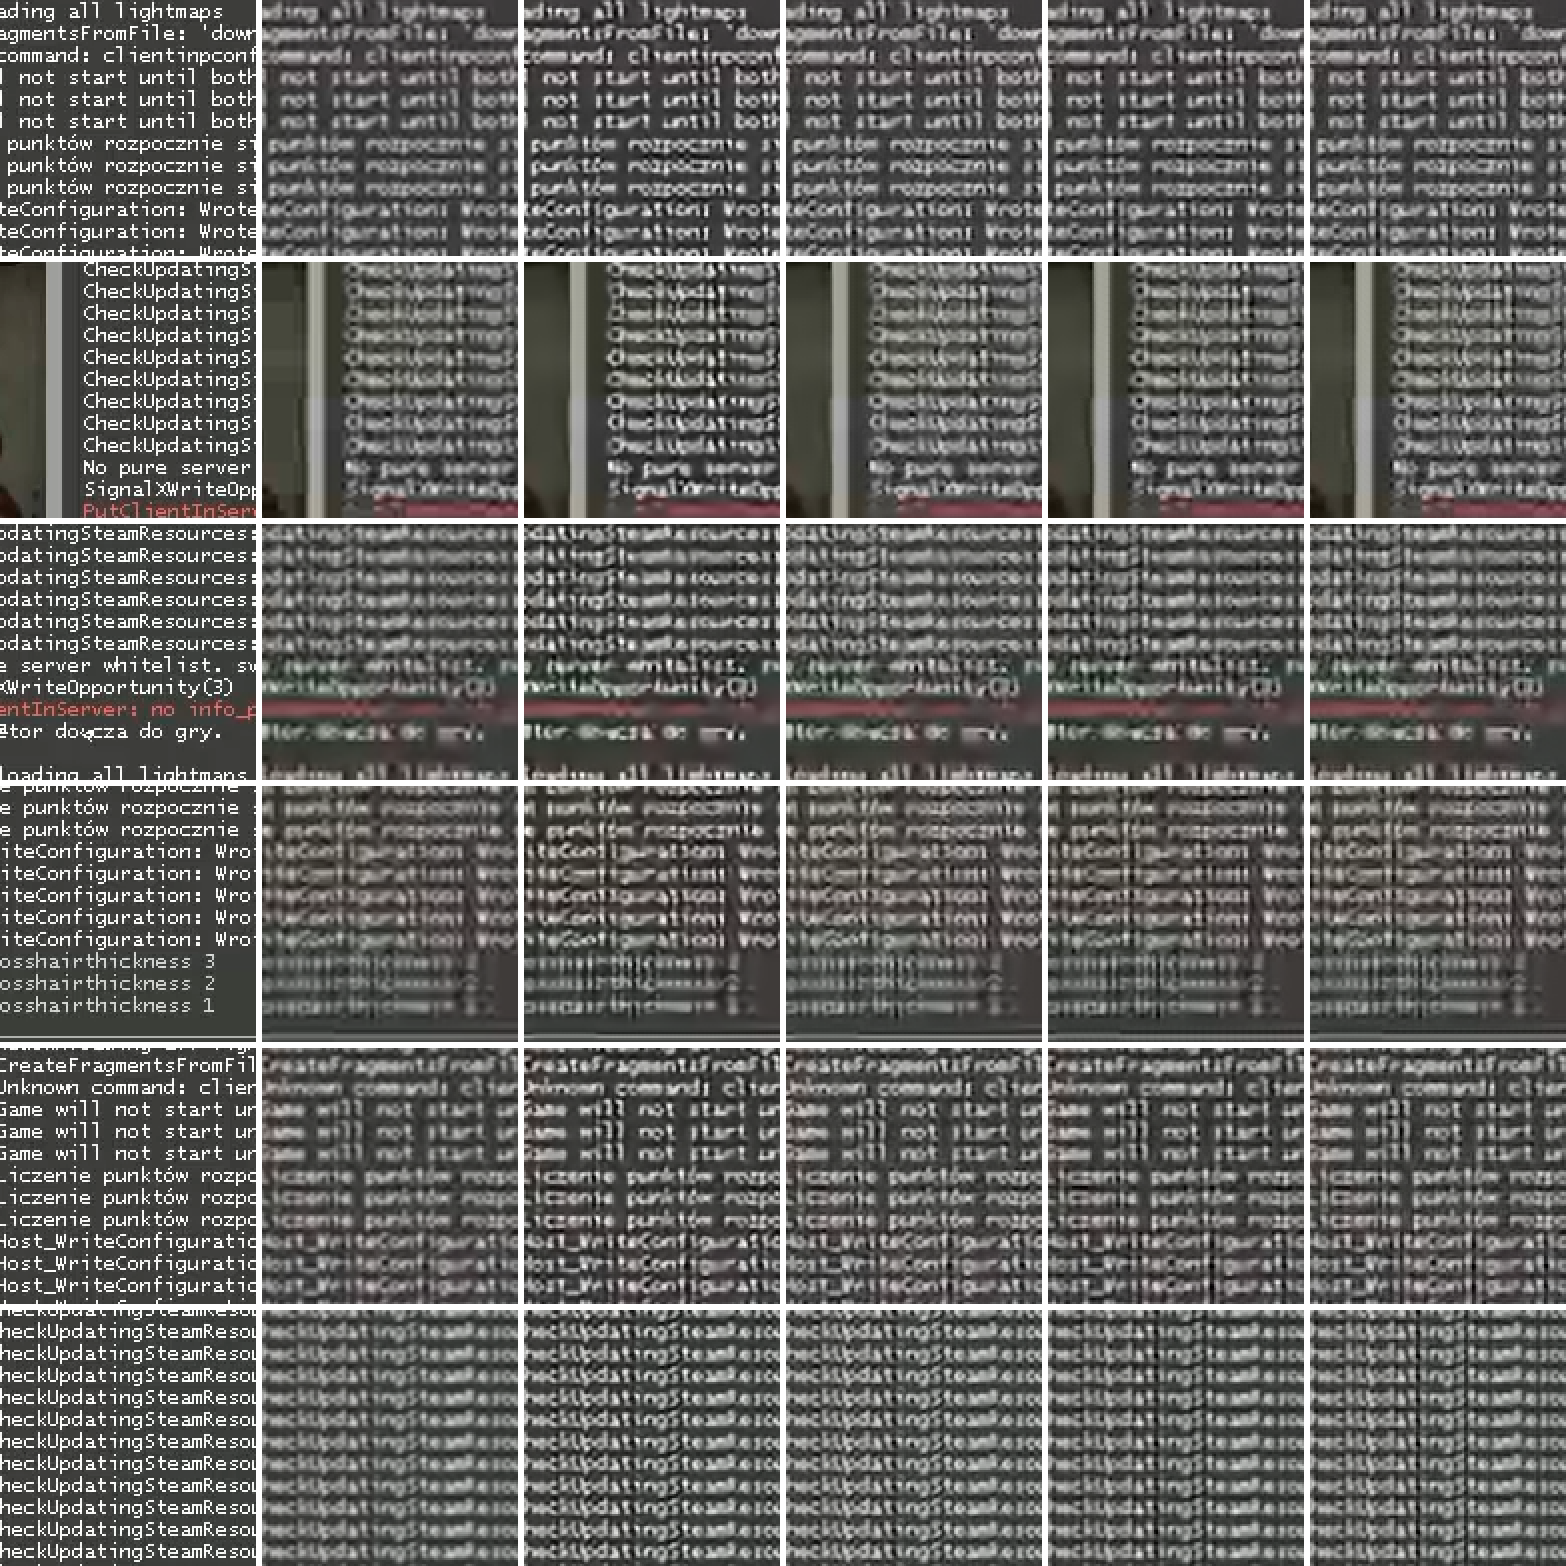

screens: IPhone (slice QP 21), Personal_computer (slice QP 26), Personal_computer (slice QP 33), IPhone (slice QP 13), Computer (slice QP 20), Web_page (slice QP 40)


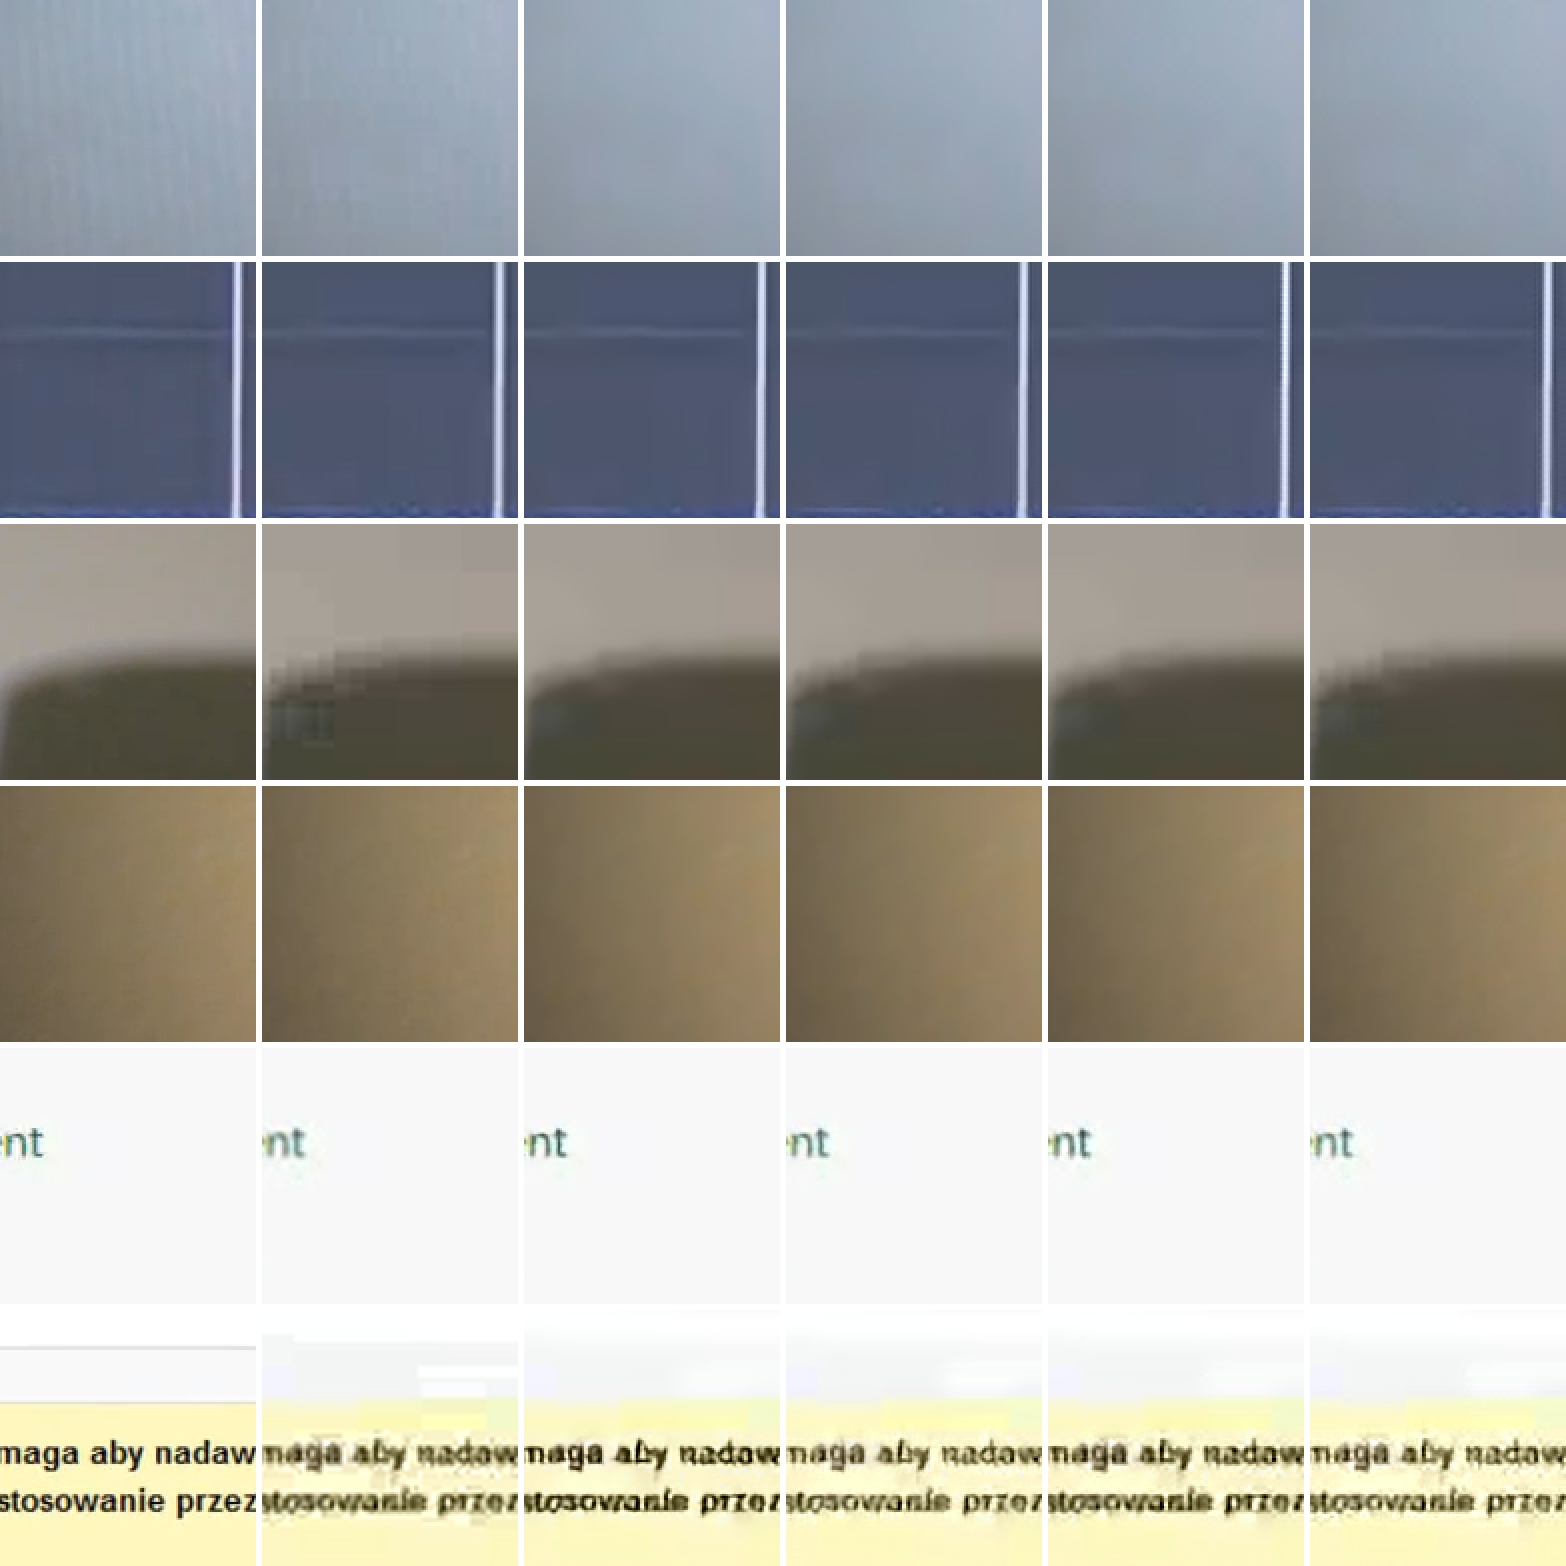

In [8]:
COLUMNS = ["truth", "bicubic", *[f"{body}, {loss}" for body in BODIES for loss in LOSSES]]


def to_uint8(x):
    return (x.clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()


def mosaic(columns, path, zoom=2, gap=6):
    """{name: uint8 (N, H, W, 3)} side by side, a picture a row, written as a PNG at `zoom` x (nearest)."""
    first = next(iter(columns.values()))
    n, h, w = first.shape[:3]
    canvas = np.full((n * (h * zoom + gap) - gap, len(columns) * (w * zoom + gap) - gap, 3), 255, np.uint8)
    for c, images in enumerate(columns.values()):
        for r, image in enumerate(images):
            y, x = r * (h * zoom + gap), c * (w * zoom + gap)
            canvas[y:y + h * zoom, x:x + w * zoom] = image.repeat(zoom, 0).repeat(zoom, 1)
    Image.fromarray(canvas).save(path)
    return path


@torch.no_grad()
def patch_pictures(indices):
    """{column: uint8 pictures} of these validation patches."""
    batch = [val_set[int(i)] for i in indices]
    lr = torch.stack([b[0][0] for b in batch]).to(DEVICE)
    condition = torch.stack([b[0][1] for b in batch]).to(DEVICE)
    hr = torch.stack([b[1] for b in batch])
    out = {"truth": to_uint8(hr), "bicubic": to_uint8(trim(models.bicubic(lr, SCALE)))}
    for body in BODIES:
        for loss in LOSSES:
            out[f"{body}, {loss}"] = to_uint8(trim(trained[body, loss, 0](lr, condition)))
    return out


@torch.no_grad()
def luma_gap(a, b):
    """Per patch, the mean absolute luma difference between two models' pictures (0-255)."""
    out = []
    for (lr, condition), _ in loader(val_set):
        lr, condition = lr.to(DEVICE), condition.to(DEVICE)
        ya, yb = (metrics.rgb_to_yuv(trim(m(lr, condition)).clamp(0, 1))[:, 0] for m in (a, b))
        out.append(255 * (ya - yb).abs().mean(dim=(1, 2)).cpu())
    return torch.cat(out).numpy()


gap = luma_gap(trained["told 24x2", "SSIM loss", 0], trained["told 24x2", "JND loss", 0])
print(f"told 24x2, SSIM against JND loss: mean luma difference {gap.mean():.2f} of 255 "
      f"(median {np.median(gap):.2f}, 99th percentile {np.quantile(gap, 0.99):.2f})")
most = np.argsort(gap)[::-1][:6]
screens = np.random.default_rng(0).choice(np.flatnonzero(GROUPS["screens"]), 6, replace=False)
print("columns:", " | ".join(COLUMNS))
for name, indices in (("differ_most", most), ("screens", screens)):
    print(f"{name}: " + ", ".join(f"{val_set.topic[i]} (slice QP {val_set.labels['qp'][i]:.0f})" for i in indices))
    display(Show(filename=str(mosaic(patch_pictures(indices), SAMPLES / f"patches_{name}.png"))))

Then whole frames, as the client sees them: the first validation clip of five topics, 1280×720 from its centre, frame
16 (a P frame), through the host's x264 line twice - at its default 0.46 bits a pixel (a 640×360 stream), where a still
screen settles near QP 0, and starved at 0.5 Mbit/s, where the codec's damage shows. The models run on the whole stream
frame with the client's 4 px of edge read again around it, told the frame's slice QP, loop filter and type as the client
tells them. Shown at 2× is the 320×180 window where the two told 24×2 models differ most: the truth and bicubic on the
left, then the told 24×2 (top) and the fast q24 (bottom) under the SSIM loss and the JND loss. Every whole frame is
written to `data/samples/26_jnd/frames/`, with what the stream did in `frames.json`.

each grid: truth | told 24x2, SSIM loss | told 24x2, JND loss  /  bicubic | fast q24, SSIM loss | fast q24, JND loss
Microsoft_Windows, default (0.460 bpp): slice QP 0, window at (400, 315)


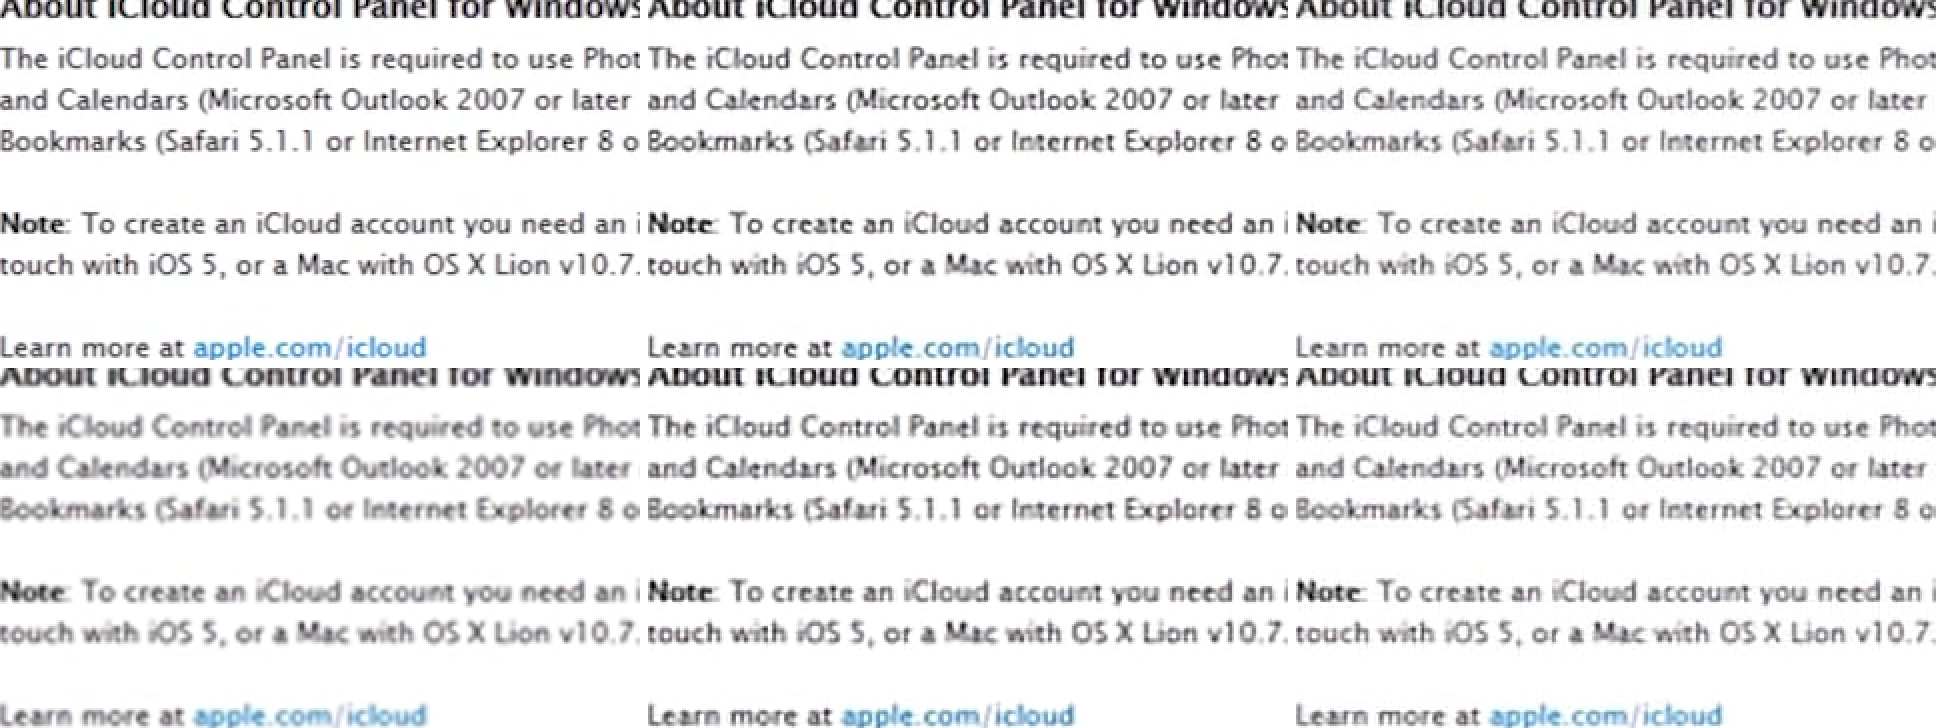

Microsoft_Windows, 0.5mbps (0.087 bpp): slice QP 16, window at (400, 315)


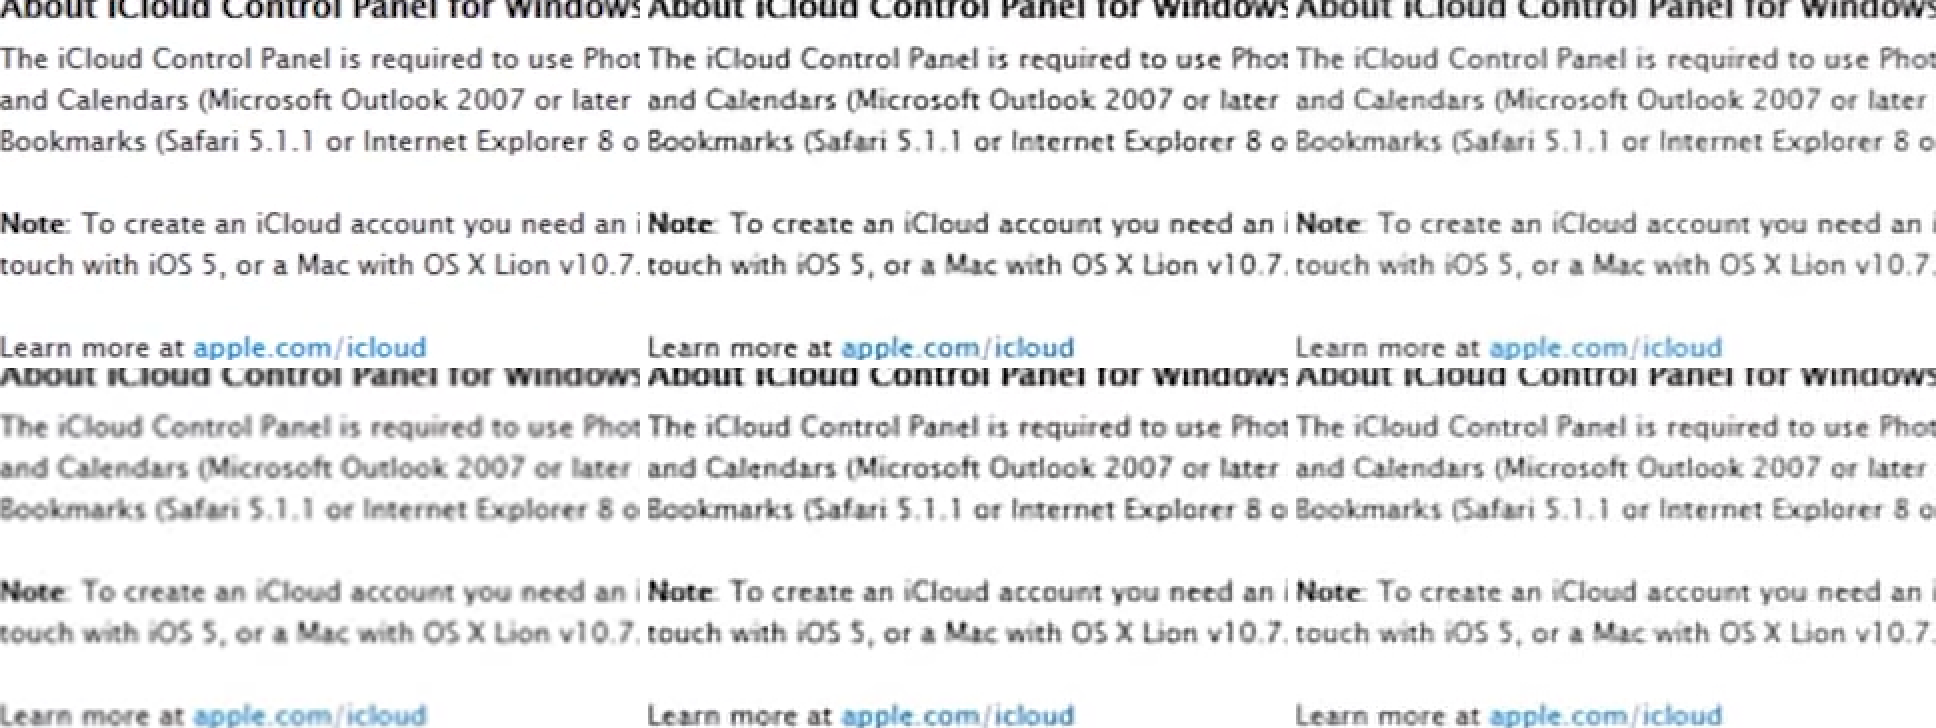

Web_page, default (0.460 bpp): slice QP 18, window at (480, 180)


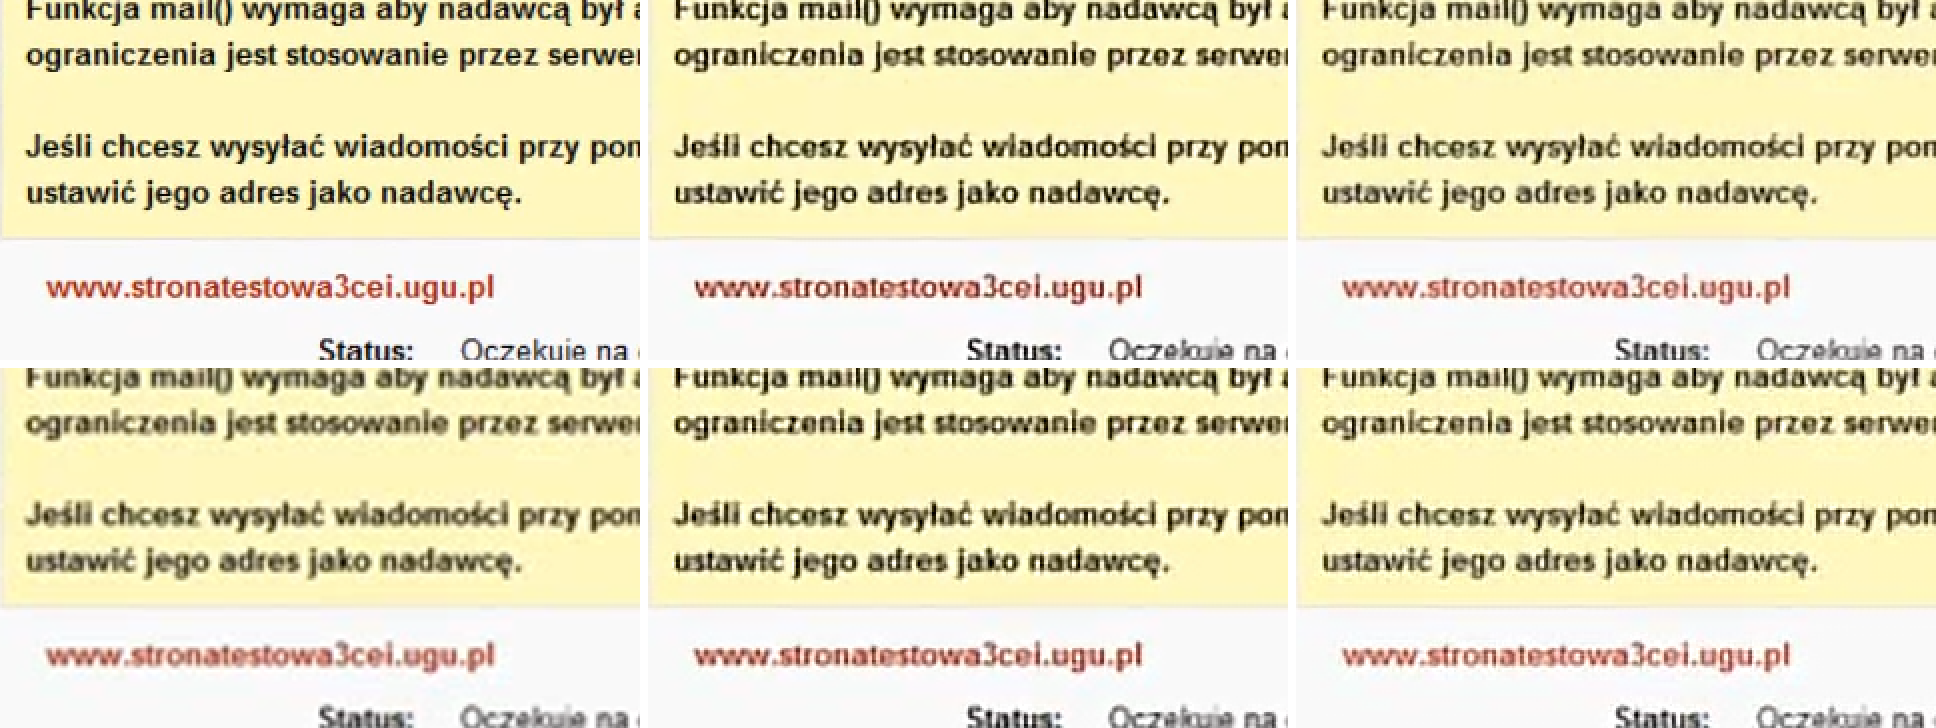

Web_page, 0.5mbps (0.072 bpp): slice QP 35, window at (480, 180)


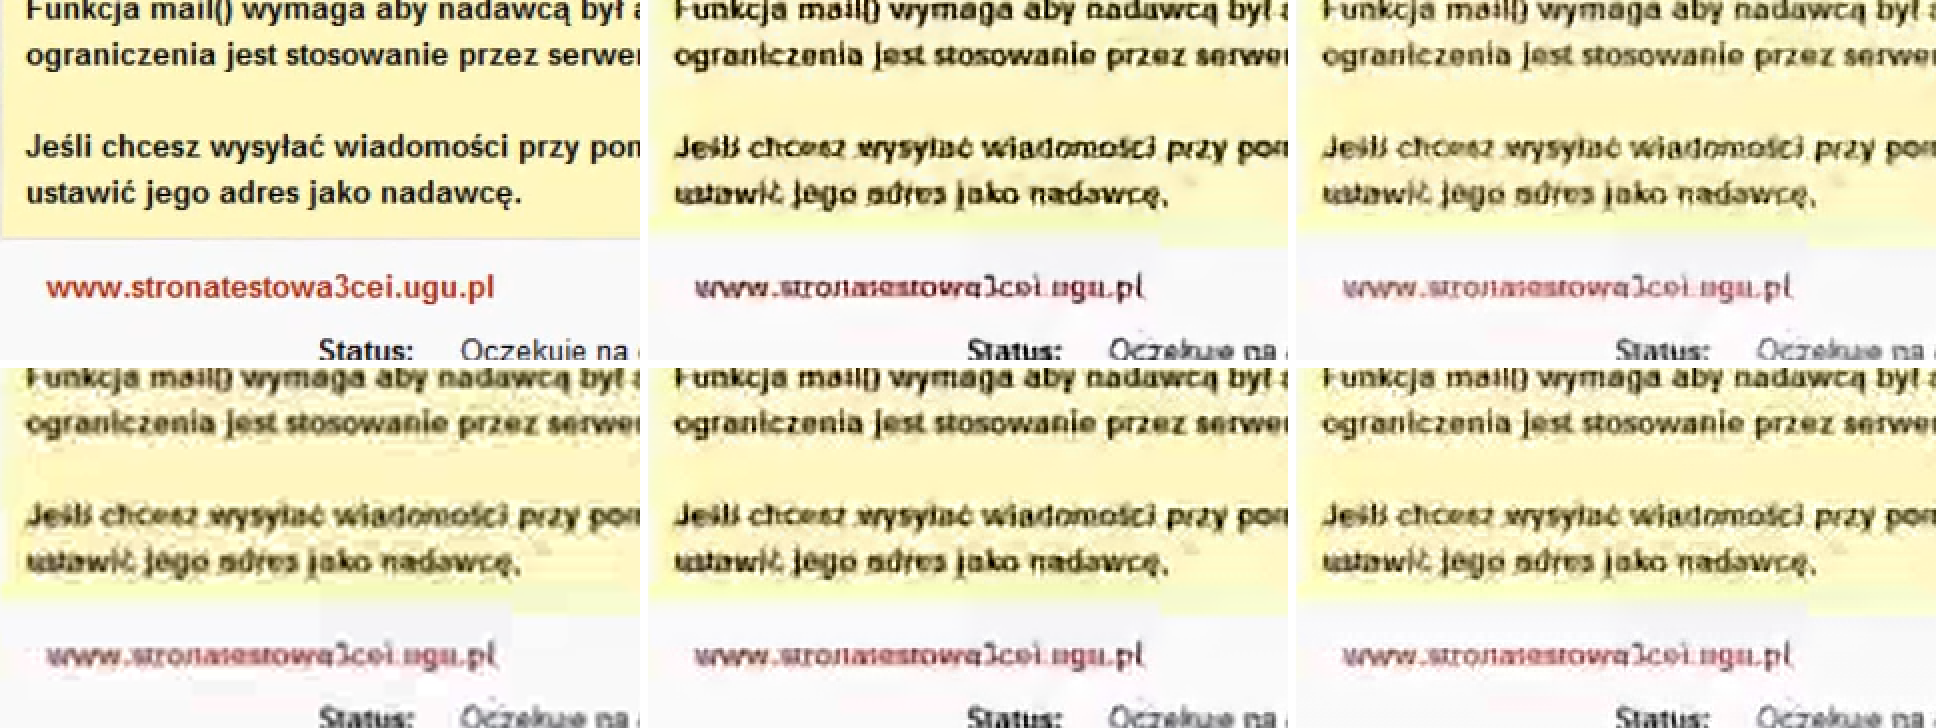

Office, default (0.460 bpp): slice QP 14, window at (720, 135)


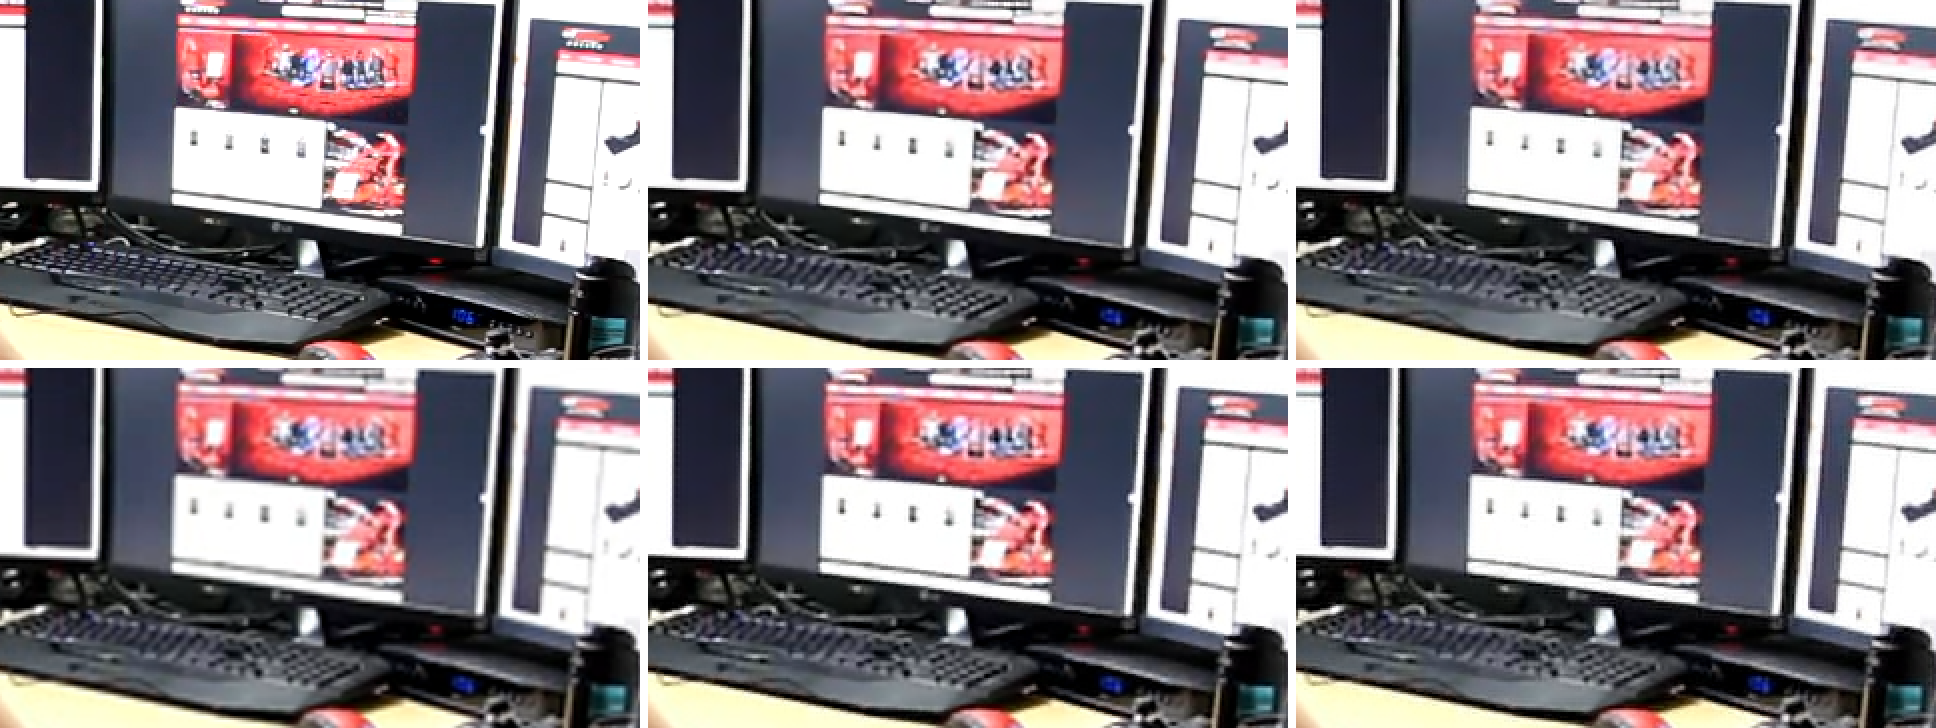

Office, 0.5mbps (0.072 bpp): slice QP 30, window at (720, 135)


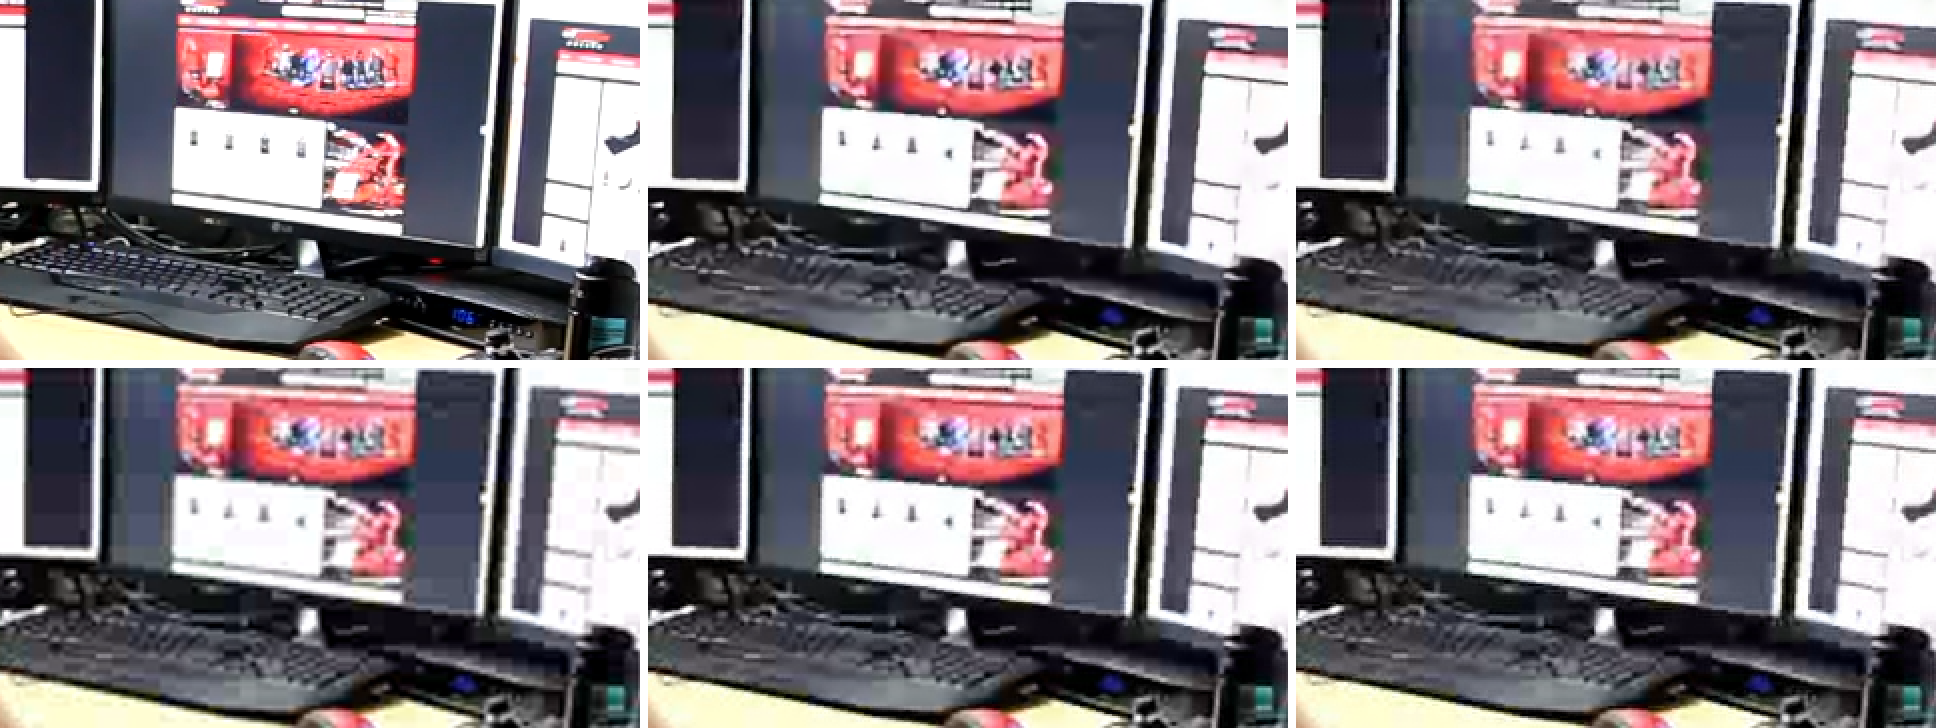

Video_game, default (0.460 bpp): slice QP 8, window at (800, 405)


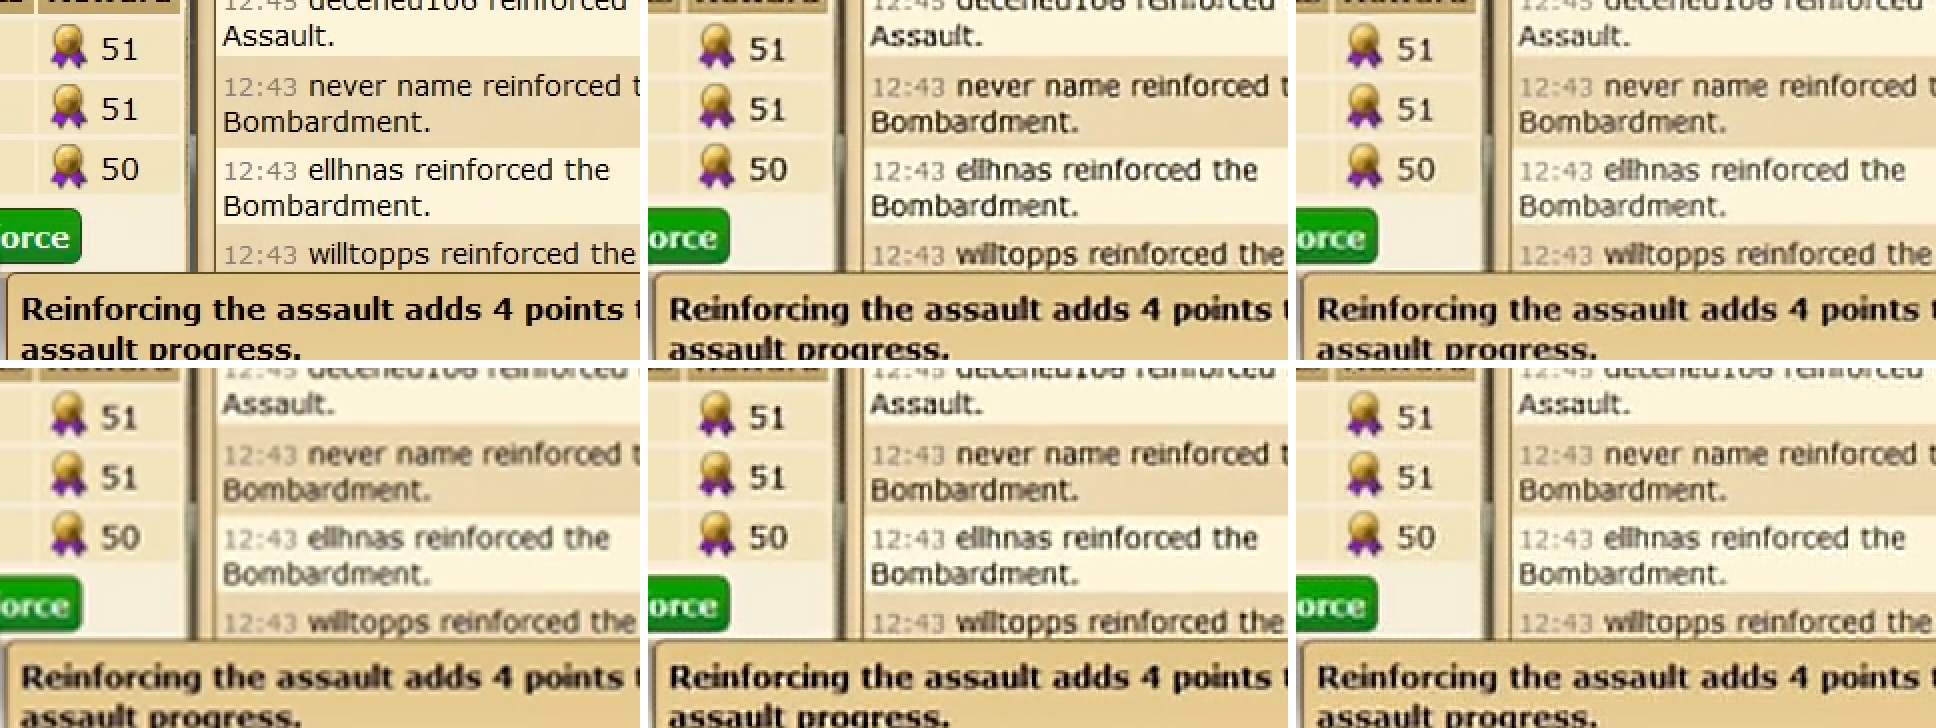

Video_game, 0.5mbps (0.087 bpp): slice QP 29, window at (800, 405)


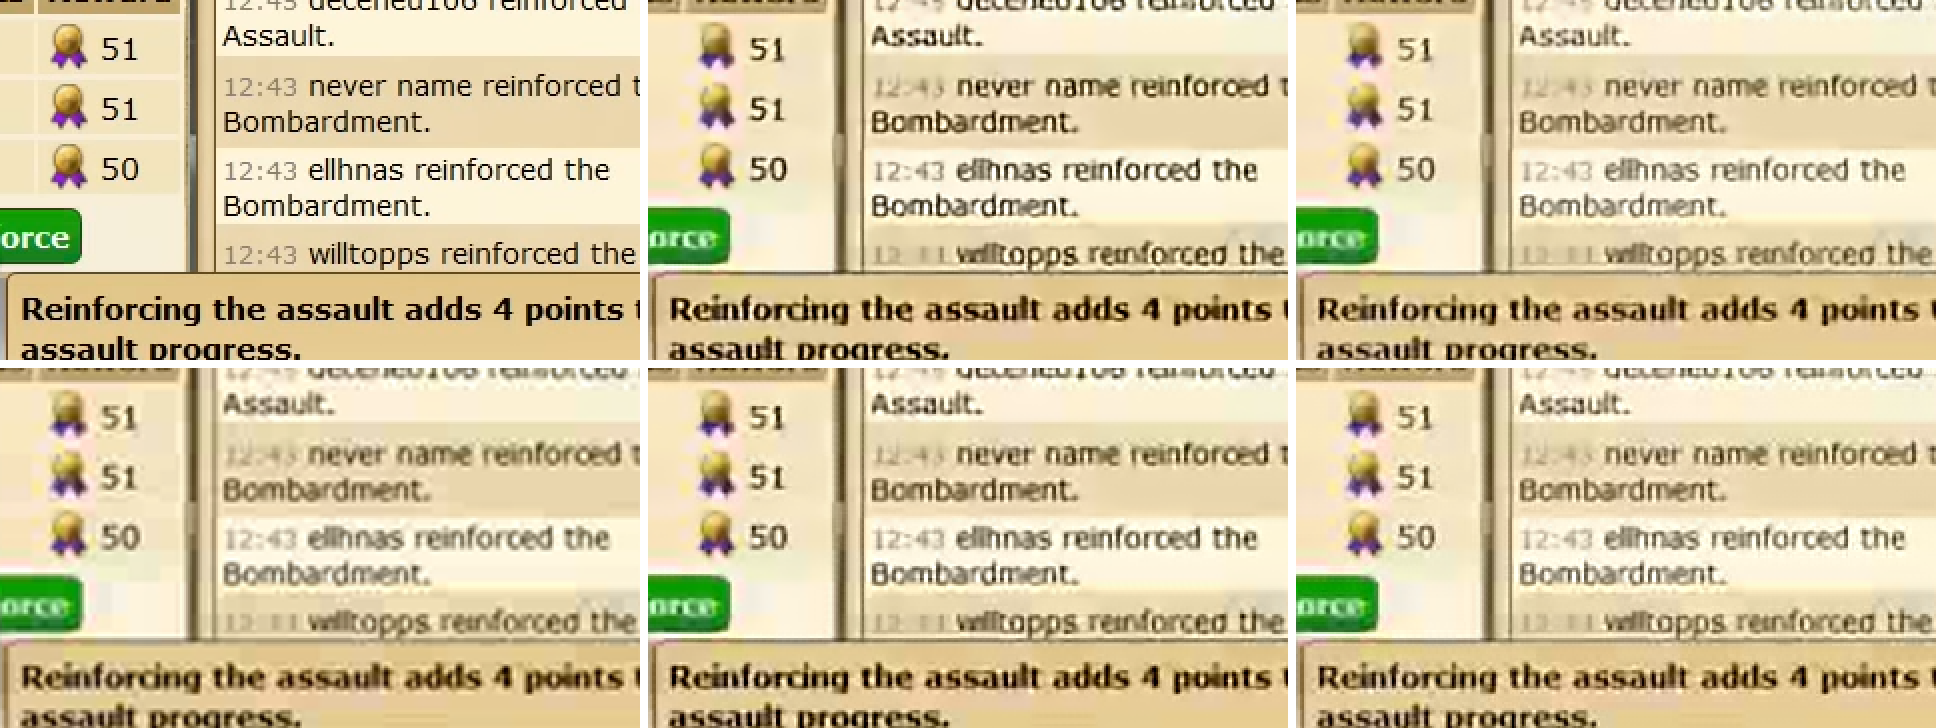

Cartoon, default (0.460 bpp): slice QP 2, window at (480, 0)


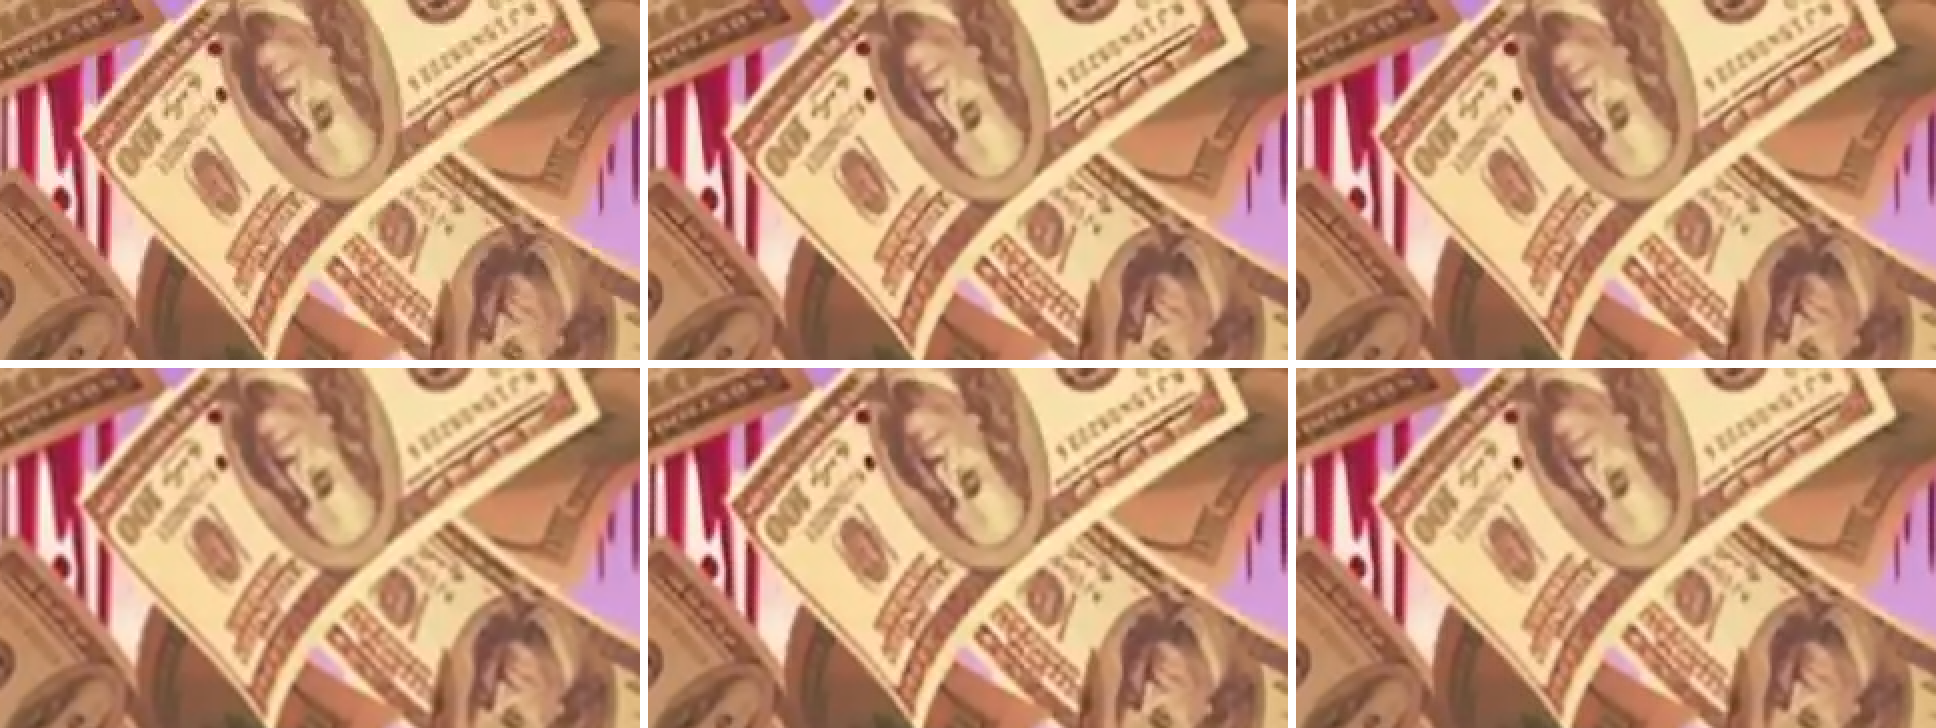

Cartoon, 0.5mbps (0.072 bpp): slice QP 26, window at (400, 0)


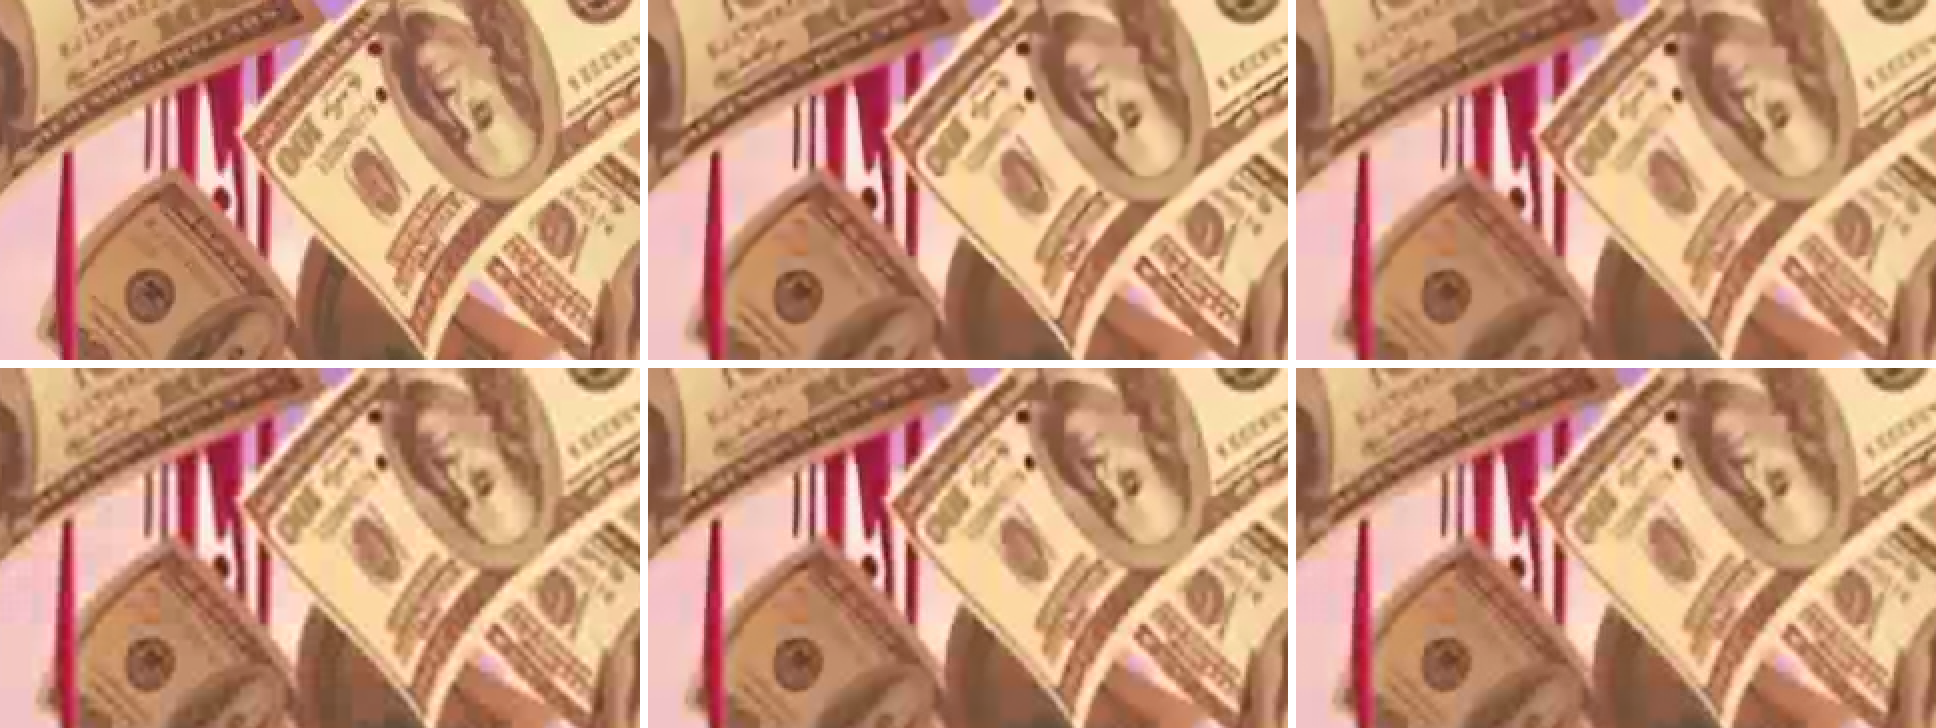

2251

In [9]:
FRAME_TOPICS = ("Microsoft_Windows", "Web_page", "Office", "Video_game", "Cartoon")
STREAMS = {"default": None, "0.5mbps": 0.5}    # the host's 0.46 bits a pixel, and a starved 0.5 Mbit/s
FRAME, CLIP_FRAMES, SIZE, WINDOW, HALO = 16, 24, (1280, 720), (180, 320), 4
LAYOUT = [["truth", "told 24x2, SSIM loss", "told 24x2, JND loss"], ["bicubic", "fast q24, SSIM loss", "fast q24, JND loss"]]
FRAMES_DIR = SAMPLES / "frames"
FRAMES_DIR.mkdir(exist_ok=True)
clip_paths = {f"yt8m-videos/{path.parts[-2]}/{path.stem}": path for path in sources.files("yt8m-videos", "test")}
keys = sorted({s["key"] for s in manifest["splits"]["val"]["sources"]} & set(clip_paths))
topic_of = {s["key"]: s["category"] for s in manifest["splits"]["val"]["sources"]}


def first_clip(topic):
    """The first validation clip of a topic with CLIP_FRAMES frames of 1280x720: its key, those frames from its centre,
    and its frame rate."""
    width, height = SIZE
    for key in keys:
        if topic_of[key] != topic:
            continue
        frames, fps = sources.load_sequence(clip_paths[key])
        if len(frames) >= CLIP_FRAMES and frames.shape[1] >= height and frames.shape[2] >= width:
            top, left = (frames.shape[1] - height) // 4 * 2, (frames.shape[2] - width) // 4 * 2
            return key, frames[:CLIP_FRAMES, top:top + height, left:left + width], fps
    return None, None, None


def stream_frame(frames, fps, mbps):
    """(HR, LR, condition) of frame FRAME through the host's x264 line, at `mbps` (None: its default bits a pixel)."""
    bpp = degrade.STREAM_BPP if mbps is None else mbps * 1e6 / (SIZE[0] // SCALE * SIZE[1] // SCALE * fps)
    made = degrade.Degradation(scale=SCALE, bpp=bpp, fps=fps, filter="bicubic", deblock=False, encoder="x264")
    hr, lr, _, report = degrade.degrade(frames, made, with_frames=True)
    row = report[FRAME]
    condition = np.array([row["slice_qp"] / QP_MAX, row["deblocked"], row["type"] == "I"], np.float32)
    return hr[FRAME], lr[FRAME], condition, bpp


@torch.no_grad()
def upscale_frame(model, lr, condition):
    """A whole stream frame through a model, its edge pixels read again around it as the client does."""
    x = torch.from_numpy(np.pad(lr, ((HALO, HALO), (HALO, HALO), (0, 0)), mode="edge")).permute(2, 0, 1)[None]
    x = x.float().div(255).to(DEVICE)
    c = torch.from_numpy(condition)[None, :, None, None].to(DEVICE)
    out = model(x, c)[..., HALO * SCALE:-HALO * SCALE, HALO * SCALE:-HALO * SCALE]
    return to_uint8(out)[0]


def busiest_window(a, b):
    """The (top, left) of the WINDOW where two pictures' luma differs most, on a grid of quarter windows."""
    luma = np.array([0.2126, 0.7152, 0.0722])
    diff = torch.from_numpy(np.abs(a.astype(np.float32) @ luma - b.astype(np.float32) @ luma))[None, None]
    sums = torch.nn.functional.avg_pool2d(diff, WINDOW, stride=(WINDOW[0] // 4, WINDOW[1] // 4))[0, 0].numpy()
    y, x = np.unravel_index(np.argmax(sums), sums.shape)
    return y * WINDOW[0] // 4, x * WINDOW[1] // 4


def grid(pictures, layout, path, zoom=2, gap=8):
    """Pictures placed as `layout` (rows of names), at `zoom` x with no smoothing, written as a PNG."""
    h, w = next(iter(pictures.values())).shape[:2]
    canvas = np.full((len(layout) * (h * zoom + gap) - gap, len(layout[0]) * (w * zoom + gap) - gap, 3), 255, np.uint8)
    for r, row in enumerate(layout):
        for c, name in enumerate(row):
            y, x = r * (h * zoom + gap), c * (w * zoom + gap)
            canvas[y:y + h * zoom, x:x + w * zoom] = pictures[name].repeat(zoom, 0).repeat(zoom, 1)
    Image.fromarray(canvas).save(path)
    return path


facts = {}
print("each grid: " + " | ".join(LAYOUT[0]) + "  /  " + " | ".join(LAYOUT[1]))
for topic in FRAME_TOPICS:
    key, frames, fps = first_clip(topic)
    if key is None:
        print(f"{topic}: no clip of 1280x720 and {CLIP_FRAMES} frames")
        continue
    for stream, mbps in STREAMS.items():
        hr, lr, condition, bpp = stream_frame(frames, fps, mbps)
        pictures = {"truth": hr, "bicubic": upscale_frame(Bicubic(), lr, condition)}
        for body in BODIES:
            for loss in LOSSES:
                pictures[f"{body}, {loss}"] = upscale_frame(trained[body, loss, 0], lr, condition)
        name = f"{topic}_{stream}"
        for label, picture in pictures.items():
            Image.fromarray(picture).save(FRAMES_DIR / f"{name}_{label.replace(', ', '_').replace(' ', '_')}.png")
        facts[name] = {"topic": topic, "clip": key, "frame": FRAME, "stream": stream, "bpp": round(bpp, 4),
                       "slice_qp": round(float(condition[0] * QP_MAX)), "deblocked": bool(condition[1]),
                       "intra": bool(condition[2]), "encoder": "x264"}
        top, left = busiest_window(pictures["told 24x2, SSIM loss"], pictures["told 24x2, JND loss"])
        window = {label: p[top:top + WINDOW[0], left:left + WINDOW[1]] for label, p in pictures.items()}
        print(f"{topic}, {stream} ({bpp:.3f} bpp): slice QP {facts[name]['slice_qp']}, window at ({left}, {top})")
        display(Show(filename=str(grid(window, LAYOUT, SAMPLES / f"frame_{name}.png"))))
(FRAMES_DIR / "frames.json").write_text(json.dumps(facts, indent=1), encoding="utf-8")

## 6. What kind of difference

The scores say how much; this says what. On the validation patches, both seeds of each model: how much of the truth's
fine detail it keeps (the mean |Laplacian| of luma, over the truth's), its mean luma bias, and its luma error at the
truth's strongest edges (the top fifth of |Laplacian| in each patch) and everywhere else, in 8-bit levels. Then on the
whole frames above, where the stream's grid is known, how much larger a step in luma is across a seam than anywhere
else (1 is no seam): between LR pixels (every 2 HR px), between the fast q24's 2×2 LR cells (every 4) and between the
codec's macroblocks (every 16).

In [10]:
LAPLACE = torch.tensor([[0.0, 1, 0], [1, -4, 1], [0, 1, 0]], device=DEVICE)[None, None]


@torch.no_grad()
def character(model):
    """Detail kept, luma bias, and the error at edges and elsewhere, over the validation patches."""
    total = {"detail": 0.0, "truth_detail": 0.0, "bias": 0.0, "edges": 0.0, "flat": 0.0}
    for (lr, condition), hr in loader(val_set):
        lr, condition, hr = lr.to(DEVICE), condition.to(DEVICE), hr.to(DEVICE)
        truth = metrics.rgb_to_yuv(hr)[:, :1]
        picture = metrics.rgb_to_yuv(trim(model(lr, condition)).clamp(0, 1))[:, :1]
        lt, lp = (torch.nn.functional.conv2d(y, LAPLACE).abs() for y in (truth, picture))
        edges = (lt > lt.flatten(1).quantile(0.8, dim=1)[:, None, None, None]).float()
        error = (picture - truth).abs()[..., 1:-1, 1:-1]
        n = len(hr)
        total["detail"] += lp.mean().item() * n
        total["truth_detail"] += lt.mean().item() * n
        total["bias"] += 255 * (picture - truth).mean().item() * n
        total["edges"] += 255 * ((error * edges).sum() / edges.sum()).item() * n
        total["flat"] += 255 * ((error * (1 - edges)).sum() / (1 - edges).sum()).item() * n
    return {"detail": total["detail"] / total["truth_detail"], **{k: total[k] / len(val_set) for k in ("bias", "edges", "flat")}}


def seam(y, period):
    """The mean step in luma across seams every `period` px, over the mean step elsewhere, both axes."""
    out = []
    for a in (y, y.T):
        step = np.abs(np.diff(a, axis=1))
        on = np.arange(step.shape[1]) % period == period - 1
        out.append(step[:, on].mean() / step[:, ~on].mean())
    return float(np.mean(out))


luma = np.array([0.2126, 0.7152, 0.0722])
rows = {"bicubic": [Bicubic()], **{f"{body}, {loss}": [trained[body, loss, seed] for seed in SEEDS]
                                   for body in BODIES for loss in LOSSES}}
print(f"{'':<22}{'detail kept':>12}{'luma bias':>10}{'at edges':>10}{'elsewhere':>10}"
      f"{'seam 2 px':>11}{'seam 4 px':>11}{'seam 16 px':>12}")
for name in ["truth", *rows]:
    if name == "truth":
        cells = ["", "", "", ""]
    else:
        each = [character(model) for model in rows[name]]
        cells = [f"{np.mean([c[key] for c in each]):.3f}" for key in ("detail", "bias", "edges", "flat")]
    label = name.replace(", ", "_").replace(" ", "_")
    frames = [np.asarray(Image.open(FRAMES_DIR / f"{frame}_{label}.png")).astype(np.float64) @ luma for frame in facts]
    seams = [np.mean([seam(y, period) for y in frames]) for period in (2, 4, 16)]
    print(f"{name:<22}" + "".join(f"{cell:>{width}}" for cell, width in zip(cells, (12, 10, 10, 10)))
          + "".join(f"{s:{width}.3f}" for s, width in zip(seams, (11, 11, 12))))

                       detail kept luma bias  at edges elsewhere  seam 2 px  seam 4 px  seam 16 px
truth                                                                 1.043      1.087       1.076
bicubic                      0.445     0.011    10.899     2.536      1.063      1.094       1.153
told 24x2, SSIM loss         0.570    -0.155     8.807     2.318      1.210      1.165       1.151
told 24x2, JND loss          0.550     0.333     9.318     2.372      1.176      1.153       1.155
fast q24, SSIM loss          0.540    -0.144     9.607     2.402      1.292      1.272       1.234
fast q24, JND loss           0.569     0.388     9.872     2.450      1.193      1.220       1.213


## 7. What it says

Run 2026-11-19 on notebook 21's 9,628 validation patches; each model the mean of seeds 0 and 1. The JND loss uses
`helpers/jnd_settings.json` (masking exponent 1.2, tiles pooled at β = 16). The JND and MOS columns use the same
settings, so they do not compare with round 1's, which used the spec's defaults (bicubic 3.60 here, 4.75 there). The
other columns do. Bold is the better of a body's two losses.

| | SSIM-Y | luma dB | JND | MOS | LPIPS | GMSD | detail kept | seam every 2 px |
|---|---|---|---|---|---|---|---|---|
| truth | | | | | | | 1 | 1.043 |
| bicubic | 0.9045 | 33.55 | 3.60 | 3.152 | 0.1556 | 0.0712 | 0.445 | 1.063 |
| told 24×2, SSIM loss | **0.9288** | **35.08** | **2.98** | **3.384** | **0.1208** | **0.0567** | **0.570** | 1.210 |
| told 24×2, JND loss | 0.9209 | 34.79 | 3.07 | 3.365 | 0.1249 | 0.0599 | 0.550 | **1.176** |
| fast q24, SSIM loss | **0.9212** | **34.47** | 3.17 | 3.306 | 0.1289 | **0.0600** | 0.540 | 1.292 |
| fast q24, JND loss | 0.9147 | 34.31 | **3.14** | **3.314** | **0.1279** | 0.0616 | **0.569** | **1.193** |

The JND-loss models of both rounds, on the judges that did not change with the settings:

| JND loss | SSIM-Y | luma dB | LPIPS | GMSD | detail kept | seam every 2 px |
|---|---|---|---|---|---|---|
| told 24×2, the spec's defaults (round 1) | **0.9224** | **34.97** | **0.1231** | **0.0587** | **0.588** | **1.160** |
| told 24×2, these settings | 0.9209 | 34.79 | 0.1249 | 0.0599 | 0.550 | 1.176 |
| fast q24, the spec's defaults (round 1) | **0.9159** | **34.48** | **0.1261** | **0.0604** | **0.599** | **1.171** |
| fast q24, these settings | 0.9147 | 34.31 | 0.1279 | 0.0616 | 0.569 | 1.193 |

- **These settings train worse models than the spec's defaults**, for both bodies and on every judge above: LPIPS
  0.0018 worse for each (the seeds land 0.0004-0.0012 apart), GMSD 0.0012, SSIM-Y 0.0012-0.0015, 0.17-0.18 dB, and
  less of the truth's fine detail kept (0.55-0.57 against 0.59-0.60). A likely cause, not tested here: at β = 16 a
  patch's d is close to its worst tile's, so of a 128 px patch's 2×2 tiles one takes most of the gradient, and a
  masking exponent of 1.2 forgives more error in busy texture, which is where an upscaler's error is.
- **The told 24×2 stays on the SSIM loss**, by more than in round 1: LPIPS 0.1249 against 0.1208 (closer on 38% of
  the patches), and it loses even on the JND it trained for (3.07 against 2.98).
- **The fast q24 is still a little better on the JND loss** by LPIPS: 0.1279 against 0.1289, closer on 55% of the
  patches (64% in round 1), 57% of the screens and 62% of the games, but not on camera and animation (48%). It
  keeps round 1's gain on the pixel grid (1.19 against 1.29, the truth 1.04) and more of the detail (0.569 against
  0.540), for 0.0065 SSIM-Y and 0.17 dB.
- Seen at 2× on the whole-frame crops: on the Windows desktop the fast q24's JND-loss text is crisper and darker than
  its SSIM-loss text; on the web page the SSIM loss's text comes out heavier, with a doubled stroke, though the JND
  scores that crop worse for the JND model; the told 24×2's two pictures of the office and the game are hard to tell
  apart. The two told models' pictures are 1.40 levels of 255 apart on average (1.3 in round 1).
- **What people saw.** Round 1's blind A/B (one viewer, the 20 whole-frame crops, 2026-11-17) preferred the
  spec-default JND loss in 11 pairs, the SSIM loss in 5 and neither in 4: 6 to 3 for the told 24×2 and 5 to 2 for the
  fast q24. Its run files are in `checkpoints/jnd_runs/_spec_defaults/`, its pictures and votes in
  `data/samples/26_jnd/_spec_defaults/`. Round 2 puts the models above on the same 20 windows in the same page, which
  is waiting for votes.

Nothing is exported: the client's graphs are notebook 23's and 24's as they were. On these numbers the JND q24 to
export is still round 1's, `checkpoints/jnd_runs/_spec_defaults/fast_q24_seed1.pt`, through notebook 24's export.